# Лабораторная работа №3. Решающее дерево

Датасеты, разбиение и метрики — те же, что в лабораторной №1:
- **Bank Marketing** — классификация, ROC-AUC (основная), PR-AUC, F1;
- **Metro Interstate Traffic Volume** — регрессия, MAE, RMSE, R², разбиение по времени.

In [1]:
# Подключаем пакет mllabs и библиотеки
import os, sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
os.environ["PYTHONPATH"] = str(ROOT)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

from mllabs import data as D
from mllabs.evaluation import (ResultStore, Timer, classification_metrics, compare_cv,
                               oof_threshold, regression_metrics)
from mllabs.models.tree import DecisionTreeClassifierScratch, DecisionTreeRegressorScratch
from mllabs.pipelines import bank_preprocessor, metro_preprocessor

pd.set_option("display.precision", 4)
sns.set_theme(style="whitegrid")
store = ResultStore("lab3_decision_tree", "Решающее дерево")
RS = D.RANDOM_STATE

In [2]:
# Разбиения те же, что в остальных лабораторных
Xb_train, Xb_test, yb_train, yb_test = D.bank_split()
Xm_train, Xm_test, ym_train, ym_test = D.metro_split()
bank_cv, metro_cv = D.bank_cv(), D.metro_cv()

## 2. Бейзлайн

Общие признаки бейзлайна, модели `DecisionTreeClassifier` / `DecisionTreeRegressor` с параметрами по умолчанию: дерево растёт, пока листья не станут чистыми.

In [3]:
# Бейзлайн-деревья для обеих задач
tree_clf_base = make_pipeline(bank_preprocessor(), DecisionTreeClassifier(random_state=RS))
with Timer() as t:
    tree_clf_base.fit(Xb_train, yb_train)
store.add("classification", "baseline", "DecisionTreeClassifier()",
          classification_metrics(yb_test, tree_clf_base.predict_proba(Xb_test)[:, 1]), t.seconds)

tree_reg_base = make_pipeline(metro_preprocessor(rich=False), DecisionTreeRegressor(random_state=RS))
with Timer() as t:
    tree_reg_base.fit(Xm_train, ym_train)
store.add("regression", "baseline", "DecisionTreeRegressor()",
          regression_metrics(ym_test, tree_reg_base.predict(Xm_test)), t.seconds)

print("Бейзлайн-дерево классификации: глубина", tree_clf_base[-1].get_depth(),
      "| листьев", tree_clf_base[-1].get_n_leaves())
print("Бейзлайн-дерево регрессии: глубина", tree_reg_base[-1].get_depth(),
      "| листьев", tree_reg_base[-1].get_n_leaves())
display(store.table("classification"))
display(store.table("regression"))

Бейзлайн-дерево классификации: глубина 47 | листьев 4771
Бейзлайн-дерево регрессии: глубина 38 | листьев 32289


,model,ROC-AUC,PR-AUC,F1,Precision,Recall,threshold,fit_seconds
Этап,,,,,,,,
Бейзлайн sklearn,DecisionTreeClassifier(),0.6134,0.1769,0.3132,0.299,0.3289,0.5,0.5355


,model,MAE,RMSE,R2,fit_seconds
Этап,,,,,
Бейзлайн sklearn,DecisionTreeRegressor(),377.7539,664.7666,0.8861,0.1805


**Выводы по бейзлайну.** Неограниченные деревья сильно переобучаются:
- в классификации дерево глубиной 47 с 4771 листом, ROC-AUC = 0.613. Почти все листья чистые, поэтому вероятности равны 0 или 1, и ранжировать клиентов невозможно;
- в регрессии 32 289 листьев на 32 460 объектов — дерево фактически запомнило обучающую выборку. R² = 0.886, MAE ≈ 378.

## 3. Улучшение бейзлайна

### 3.1. Гипотезы

**Классификация:**
1. Неограниченное дерево переобучается: почти каждый лист содержит один-два объекта, и вероятности получаются 0 или 1. **Ограничение глубины** должно помочь.
2. **Минимальный размер листа**: лист из сотни клиентов даёт осмысленную долю согласий, а значит, хорошее ранжирование.
3. **Новые признаки** из лабораторных 1–2 (логарифмы, флаг «раньше звонили»). Ожидаем, что эффекта **не будет**: дереву безразличны монотонные преобразования, порог по `log(x)` эквивалентен порогу по `x`. Масштабирование не проверяем по той же причине.
4. **Веса классов** — поднимают F1 при пороге 0.5, но ранжирование почти не меняют.

**Регрессия:**
1. **Регуляризация размера листа** — при 32 тысячах часов лист из одного наблюдения запоминает шум.
2. **Новые признаки:** тип дня и праздник на весь день (дереву не надо будет «собирать» выходные из `dayofweek > 4`), очищенная погода.

In [4]:
# Проверка гипотез для классификации
clf_scoring = {"ROC-AUC": "roc_auc", "PR-AUC": "average_precision", "F1": "f1"}
clf_hyp = compare_cv({
    "0. Бейзлайн": make_pipeline(bank_preprocessor(), DecisionTreeClassifier(random_state=RS)),
    "1. max_depth=6": make_pipeline(bank_preprocessor(), DecisionTreeClassifier(max_depth=6, random_state=RS)),
    "2. min_samples_leaf=100": make_pipeline(bank_preprocessor(),
                                             DecisionTreeClassifier(min_samples_leaf=100, random_state=RS)),
    "3. + новые признаки": make_pipeline(bank_preprocessor(rich=True),
                                         DecisionTreeClassifier(min_samples_leaf=100, random_state=RS)),
    "4. + class_weight=balanced": make_pipeline(
        bank_preprocessor(), DecisionTreeClassifier(min_samples_leaf=100, class_weight="balanced", random_state=RS)),
}, Xb_train, yb_train, bank_cv, clf_scoring)
clf_hyp

,ROC-AUC,ROC-AUC std,PR-AUC,PR-AUC std,F1,F1 std
Гипотеза,,,,,,
0. Бейзлайн,0.6152,0.0122,0.1773,0.0097,0.3145,0.0194
1. max_depth=6,0.7054,0.0081,0.3048,0.0078,0.2843,0.0181
2. min_samples_leaf=100,0.7661,0.0073,0.4032,0.0057,0.3022,0.0215
3. + новые признаки,0.7660,0.0075,0.4033,0.0055,0.3022,0.0215
4. + class_weight=balanced,0.7585,0.0070,0.4023,0.0084,0.3611,0.0154


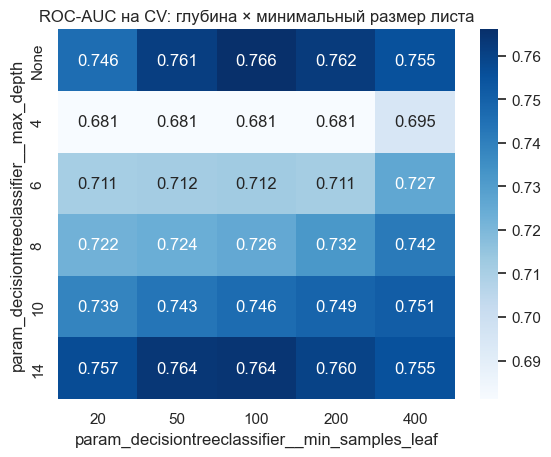

Лучшие параметры: {'decisiontreeclassifier__max_depth': None, 'decisiontreeclassifier__min_samples_leaf': 100} | ROC-AUC CV: 0.7661


In [5]:
# Подбор глубины и размера листа по ROC-AUC
clf_search = GridSearchCV(
    make_pipeline(bank_preprocessor(), DecisionTreeClassifier(random_state=RS)),
    {"decisiontreeclassifier__max_depth": [4, 6, 8, 10, 14, None],
     "decisiontreeclassifier__min_samples_leaf": [20, 50, 100, 200, 400]},
    scoring="roc_auc", cv=bank_cv, n_jobs=-1)
clf_search.fit(Xb_train, yb_train)
grid = pd.DataFrame(clf_search.cv_results_).pivot(
    index="param_decisiontreeclassifier__max_depth",
    columns="param_decisiontreeclassifier__min_samples_leaf", values="mean_test_score")
grid.index = grid.index.map(lambda d: "None" if pd.isna(d) else int(d))
sns.heatmap(grid, annot=True, fmt=".3f", cmap="Blues")
plt.title("ROC-AUC на CV: глубина × минимальный размер листа")
plt.show()
print("Лучшие параметры:", clf_search.best_params_, "| ROC-AUC CV:", round(clf_search.best_score_, 4))

In [6]:
# Проверка гипотез для регрессии
reg_scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}
TREE_NUM = ["hour", "dayofweek", "month", "is_holiday", "is_weekend"] + D.METRO_WEATHER
TREE_CAT = ["daytype", "weather_main"]
reg_hyp = compare_cv({
    "0. Бейзлайн": make_pipeline(metro_preprocessor(rich=False), DecisionTreeRegressor(random_state=RS)),
    "1. min_samples_leaf=10": make_pipeline(metro_preprocessor(rich=False),
                                            DecisionTreeRegressor(min_samples_leaf=10, random_state=RS)),
    "2. + тип дня и очищенная погода": make_pipeline(
        metro_preprocessor(TREE_NUM, TREE_CAT), DecisionTreeRegressor(min_samples_leaf=10, random_state=RS)),
}, Xm_train, ym_train, metro_cv, reg_scoring)
reg_hyp

,MAE,MAE std,RMSE,RMSE std,R2,R2 std
Гипотеза,,,,,,
0. Бейзлайн,390.0843,46.0196,679.3228,76.4067,0.8805,0.0259
1. min_samples_leaf=10,312.1228,41.5880,525.7575,69.7567,0.9280,0.0184
2. + тип дня и очищенная погода,291.5753,39.7284,471.1774,57.7537,0.9422,0.0147


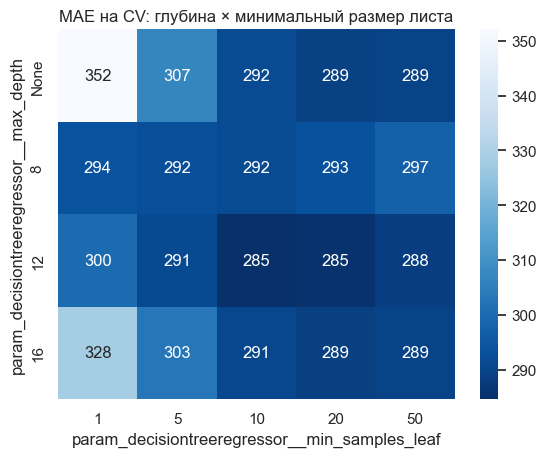

Лучшие параметры: {'decisiontreeregressor__max_depth': 12, 'decisiontreeregressor__min_samples_leaf': 10}


In [7]:
# Подбор глубины и размера листа для регрессии
reg_search = GridSearchCV(
    make_pipeline(metro_preprocessor(TREE_NUM, TREE_CAT), DecisionTreeRegressor(random_state=RS)),
    {"decisiontreeregressor__max_depth": [8, 12, 16, None],
     "decisiontreeregressor__min_samples_leaf": [1, 5, 10, 20, 50]},
    scoring="neg_mean_absolute_error", cv=metro_cv, n_jobs=-1)
reg_search.fit(Xm_train, ym_train)
grid = -pd.DataFrame(reg_search.cv_results_).pivot(
    index="param_decisiontreeregressor__max_depth",
    columns="param_decisiontreeregressor__min_samples_leaf", values="mean_test_score")
grid.index = grid.index.map(lambda d: "None" if pd.isna(d) else int(d))
sns.heatmap(grid, annot=True, fmt=".0f", cmap="Blues_r")
plt.title("MAE на CV: глубина × минимальный размер листа")
plt.show()
print("Лучшие параметры:", reg_search.best_params_)

**Результаты проверки гипотез.**

*Классификация:*
- Ограничение глубины до 6: ROC-AUC на CV 0.615 → 0.705. Подтверждена.
- Минимальный размер листа 100 работает ещё лучше: 0.766. Лист из сотни клиентов даёт осмысленную долю согласий. Подбор по сетке подтвердил лучший вариант — **без ограничения глубины, лист ≥ 100 объектов**: дерево само останавливается там, где данных мало.
- Новые признаки: 0.7661 → 0.7660 — эффекта нет, как и ожидалось. Логарифм — монотонное преобразование, и порог по `log(x)` эквивалентен порогу по `x`.
- `class_weight="balanced"`: F1 при пороге 0.5 вырос (0.30 → 0.36), но ROC-AUC упал (0.766 → 0.759). Подбор порога даёт тот же выигрыш в F1 без потерь, поэтому от весов классов отказываемся.

*Регрессия:*
- Лист ≥ 10 объектов: MAE на CV 390 → 312. Подтверждена.
- Тип дня, праздник на весь день и очищенная погода: MAE 312 → 292. Подтверждена: дереву не нужно тратить разбиения на то, чтобы «собрать» выходные из `dayofweek`.
- Лучшие параметры: **глубина 12, лист ≥ 10**.

### 3.2. Улучшенный бейзлайн

In [8]:
# Классификация: лучшее дерево и порог по out-of-fold прогнозам
tree_clf_best = clf_search.best_estimator_
thr = oof_threshold(tree_clf_best, Xb_train, yb_train, bank_cv)
with Timer() as t:
    tree_clf_best.fit(Xb_train, yb_train)
cd, cl = (clf_search.best_params_[f"decisiontreeclassifier__{p}"] for p in ("max_depth", "min_samples_leaf"))
store.add("classification", "improved", f"DecisionTreeClassifier(max_depth={cd}, min_samples_leaf={cl})",
          classification_metrics(yb_test, tree_clf_best.predict_proba(Xb_test)[:, 1], thr), t.seconds)

# Регрессия: лучшее дерево
tree_reg_best = reg_search.best_estimator_
with Timer() as t:
    tree_reg_best.fit(Xm_train, ym_train)
rd, rl = (reg_search.best_params_[f"decisiontreeregressor__{p}"] for p in ("max_depth", "min_samples_leaf"))
store.add("regression", "improved", f"DecisionTreeRegressor(max_depth={rd}, min_samples_leaf={rl}) + daytype",
          regression_metrics(ym_test, tree_reg_best.predict(Xm_test)), t.seconds)

display(store.table("classification"))
display(store.table("regression"))

,model,ROC-AUC,PR-AUC,F1,Precision,Recall,threshold,fit_seconds
Этап,,,,,,,,
Бейзлайн sklearn,DecisionTreeClassifier(),0.6134,0.1769,0.3132,0.2990,0.3289,0.50,0.5355
Улучшенный sklearn,"DecisionTreeClassifier(max_depth=None, min_sam...",0.7771,0.4280,0.4745,0.4586,0.4915,0.24,0.3636


,model,MAE,RMSE,R2,fit_seconds
Этап,,,,,
Бейзлайн sklearn,DecisionTreeRegressor(),377.7539,664.7666,0.8861,0.1805
Улучшенный sklearn,"DecisionTreeRegressor(max_depth=12, min_sample...",256.4386,437.9964,0.9506,0.1496


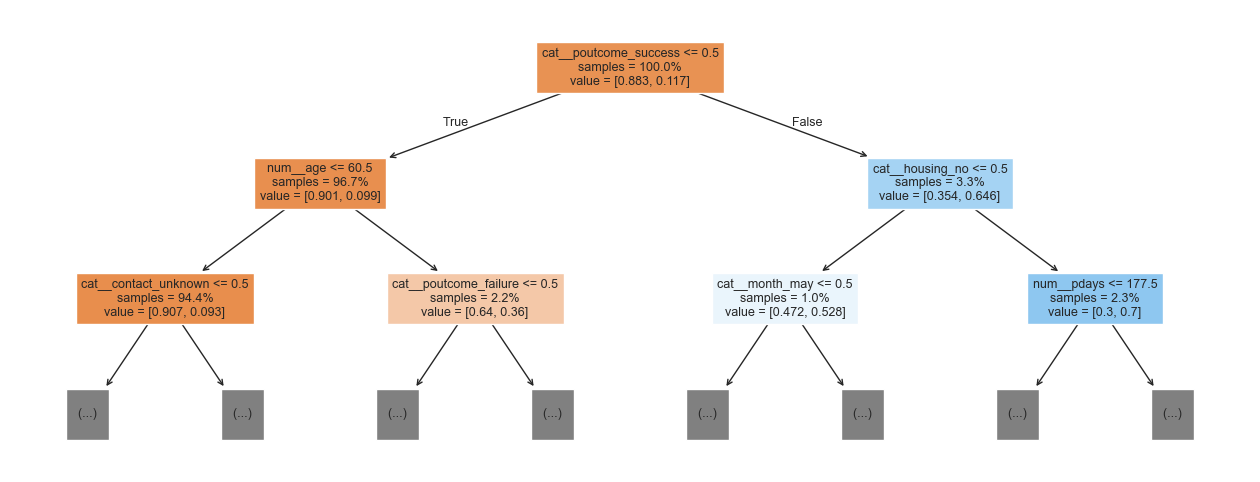

In [9]:
# Верхние уровни улучшенного дерева классификации — какие вопросы оно задаёт первыми
names = tree_clf_best[0][-1].get_feature_names_out()
plt.figure(figsize=(16, 6))
plot_tree(tree_clf_best[-1], max_depth=2, feature_names=list(names), filled=True,
          proportion=True, impurity=False, fontsize=9)
plt.show()

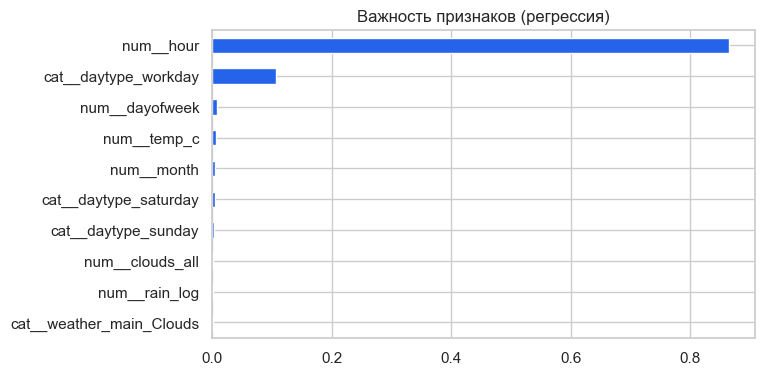

In [10]:
# Важность признаков в дереве регрессии
names = tree_reg_best[0][-1].get_feature_names_out()
imp = pd.Series(tree_reg_best[-1].feature_importances_, index=names).sort_values().tail(10)
imp.plot.barh(figsize=(7, 4), color="#2563eb")
plt.title("Важность признаков (регрессия)")
plt.show()

**Улучшенный бейзлайн против бейзлайна (тест).**

| | ROC-AUC | PR-AUC | F1 | MAE | R² |
|---|---|---|---|---|---|
| Бейзлайн | 0.613 | 0.177 | 0.313 | 377.8 | 0.886 |
| Улучшенный | **0.777** | **0.428** | **0.475** | **256.4** | **0.951** |

- Регуляризация превратила дерево из бесполезного (ROC-AUC 0.61) в сопоставимое с логистической регрессией (0.78). F1 = 0.475 — лучший результат среди лабораторных 1–3.
- Ошибка регрессии уменьшилась на треть: 378 → 256.
- Первый вопрос дерева классификации — был ли успешен прошлый контакт с клиентом. Дальше дерево делит клиентов по возрасту (старше 60 лет), наличию ипотеки и известности канала связи. В регрессии на час приходится 87% важности, ещё 11% — на признак «рабочий день».

## 4. Собственная реализация

`mllabs/models/tree.py` — CART:
- признаки заранее раскладываются по корзинам (до 64 значений: уникальные значения или квантили), как в LightGBM и `HistGradientBoosting`;
- в каждом узле одной операцией `np.bincount` строятся гистограммы числа объектов, Σw, Σwy, Σwy² по всем признакам и корзинам, после чего кумулятивные суммы дают уменьшение ошибки для всех порогов сразу;
- критерий — уменьшение взвешенной суммы квадратов отклонений (SSE). Для бинарного y ∈ {0, 1} он совпадает с критерием Джини, потому что дисперсия p(1 − p) пропорциональна индексу Джини 2p(1 − p);
- лист хранит взвешенное среднее y: долю класса 1 для классификации, средний трафик для регрессии;
- прогноз векторизован: все объекты спускаются по дереву одновременно, по одному уровню за итерацию.

Отличие от sklearn: пороги ищутся среди границ корзин, а не среди всех значений. На числовых признаках с тысячами значений (`balance`) это небольшое огрубление, и оно же работает как регуляризация.

### 4.1. Те же условия, что у бейзлайна

In [11]:
# Неограниченные деревья на признаках бейзлайна
own_clf = make_pipeline(bank_preprocessor(), DecisionTreeClassifierScratch(random_state=RS))
with Timer() as t:
    own_clf.fit(Xb_train, yb_train)
store.add("classification", "scratch", "DecisionTreeClassifierScratch()",
          classification_metrics(yb_test, own_clf.predict_proba(Xb_test)[:, 1]), t.seconds)

own_reg = make_pipeline(metro_preprocessor(rich=False), DecisionTreeRegressorScratch(random_state=RS))
with Timer() as t:
    own_reg.fit(Xm_train, ym_train)
store.add("regression", "scratch", "DecisionTreeRegressorScratch()",
          regression_metrics(ym_test, own_reg.predict(Xm_test)), t.seconds)

print("Своё дерево классификации: глубина", own_clf[-1].tree_.depth, "| листьев", own_clf[-1].tree_.n_leaves)
print("Своё дерево регрессии: глубина", own_reg[-1].tree_.depth, "| листьев", own_reg[-1].tree_.n_leaves)
display(store.table("classification").loc[["Бейзлайн sklearn", "Своя реализация"]])
display(store.table("regression").loc[["Бейзлайн sklearn", "Своя реализация"]])

Своё дерево классификации: глубина 41 | листьев 5044
Своё дерево регрессии: глубина 37 | листьев 31105


,model,ROC-AUC,PR-AUC,F1,Precision,Recall,threshold,fit_seconds
Этап,,,,,,,,
Бейзлайн sklearn,DecisionTreeClassifier(),0.6134,0.1769,0.3132,0.2990,0.3289,0.5,0.5355
Своя реализация,DecisionTreeClassifierScratch(),0.6113,0.1763,0.3111,0.3014,0.3214,0.5,3.1446


,model,MAE,RMSE,R2,fit_seconds
Этап,,,,,
Бейзлайн sklearn,DecisionTreeRegressor(),377.7539,664.7666,0.8861,0.1805
Своя реализация,DecisionTreeRegressorScratch(),377.0047,670.3759,0.8842,5.9499


**Своя реализация против бейзлайна sklearn.** Неограниченные деревья ведут себя одинаково: глубина 41 против 47, 5044 листа против 4771; ROC-AUC 0.611 против 0.613, MAE 377.0 против 377.8. Небольшие отличия объясняются тем, что своё дерево ищет пороги только на границах 64 корзин, а sklearn перебирает все значения. Алгоритм реализован верно.

### 4.2. Своя реализация с техниками улучшенного бейзлайна

In [12]:
# Переносим подобранные глубину, размер листа и признаки
own_clf_best = make_pipeline(bank_preprocessor(),
                             DecisionTreeClassifierScratch(max_depth=cd, min_samples_leaf=cl, random_state=RS))
thr_own = oof_threshold(own_clf_best, Xb_train, yb_train, bank_cv)
with Timer() as t:
    own_clf_best.fit(Xb_train, yb_train)
store.add("classification", "scratch_improved",
          f"DecisionTreeClassifierScratch(max_depth={cd}, min_samples_leaf={cl})",
          classification_metrics(yb_test, own_clf_best.predict_proba(Xb_test)[:, 1], thr_own), t.seconds)

own_reg_best = make_pipeline(metro_preprocessor(TREE_NUM, TREE_CAT),
                             DecisionTreeRegressorScratch(max_depth=rd, min_samples_leaf=rl, random_state=RS))
with Timer() as t:
    own_reg_best.fit(Xm_train, ym_train)
store.add("regression", "scratch_improved",
          f"DecisionTreeRegressorScratch(max_depth={rd}, min_samples_leaf={rl}) + daytype",
          regression_metrics(ym_test, own_reg_best.predict(Xm_test)), t.seconds)

display(store.table("classification"))
display(store.table("regression"))

,model,ROC-AUC,PR-AUC,F1,Precision,Recall,threshold,fit_seconds
Этап,,,,,,,,
Бейзлайн sklearn,DecisionTreeClassifier(),0.6134,0.1769,0.3132,0.2990,0.3289,0.50,0.5355
Улучшенный sklearn,"DecisionTreeClassifier(max_depth=None, min_sam...",0.7771,0.4280,0.4745,0.4586,0.4915,0.24,0.3636
Своя реализация,DecisionTreeClassifierScratch(),0.6113,0.1763,0.3111,0.3014,0.3214,0.50,3.1446
Своя реализация + улучшения,"DecisionTreeClassifierScratch(max_depth=None, ...",0.7675,0.4073,0.4612,0.4565,0.4660,0.24,0.9157


,model,MAE,RMSE,R2,fit_seconds
Этап,,,,,
Бейзлайн sklearn,DecisionTreeRegressor(),377.7539,664.7666,0.8861,0.1805
Улучшенный sklearn,"DecisionTreeRegressor(max_depth=12, min_sample...",256.4386,437.9964,0.9506,0.1496
Своя реализация,DecisionTreeRegressorScratch(),377.0047,670.3759,0.8842,5.9499
Своя реализация + улучшения,"DecisionTreeRegressorScratch(max_depth=12, min...",256.9017,439.7697,0.9502,0.5706


**Своя реализация с улучшениями против улучшенного sklearn.**
- Регрессия совпадает: MAE 256.9 против 256.4, R² 0.950 против 0.951.
- В классификации своё дерево уступает примерно 0.01 ROC-AUC (0.768 против 0.777). Причина — корзины: у `balance`, `age` и `day` много значений, и 64 квантильные границы иногда не позволяют найти лучший порог. В одиночном дереве это заметно, а в ансамблях (лабораторные 4–5) такое огрубление, наоборот, работает как регуляризация.
- Своё дерево обучается в 2–6 раз медленнее sklearn (Python против Cython), но всё ещё за секунды.

In [13]:
# Сохраняем метрики для итогового сравнения
print("Сохранено:", store.save().name)

Сохранено: lab3_decision_tree.json


## 5. Выводы

1. Решающее дерево без ограничений запоминает обучающую выборку. Главный инструмент улучшения — регуляризация размера листа: ROC-AUC вырос с 0.61 до 0.78, а MAE снизился с 378 до 256.
2. Дереву безразличны масштаб и монотонные преобразования признаков: масштабирование и логарифмы не дают эффекта. Помогают только признаки с новой информацией, например тип дня.
3. Лучший результат: **ROC-AUC 0.777, F1 0.475** и **MAE 256, R² 0.951**.
4. Собственная реализация (гистограммный CART) воспроизводит sklearn в регрессии и немного уступает в классификации из-за огрубления порогов.
5. Плюс дерева — интерпретируемость (правила видны на рисунке), минус — высокая дисперсия. Её снижают ансамбли из следующих лабораторных.